# Clustering QWS Dataset — Génération de la colonne `class`

**Objectif** : Appliquer le clustering K-Means sur le dataset QWS2 (2507 services web, 9 attributs QoS) pour générer une colonne `class` (Bronze / Silver / Gold) permettant la sélection de services pour une composition ultérieure.

| # | Attribut QoS | Sens | Description |
|---|---|---|---|
| 1 | Response Time | ↓ bas = mieux | Temps de réponse moyen (ms) |
| 2 | Availability | ↑ haut = mieux | Disponibilité (%) |
| 3 | Throughput | ↑ haut = mieux | Débit (req/s) |
| 4 | Successability | ↑ haut = mieux | Taux de succès (%) |
| 5 | Reliability | ↑ haut = mieux | Fiabilité (%) |
| 6 | Compliance | ↑ haut = mieux | Conformité standards (%) |
| 7 | Best Practices | ↑ haut = mieux | Bonnes pratiques (%) |
| 8 | Latency | ↓ bas = mieux | Latence (ms) |
| 9 | Documentation | ↑ haut = mieux | Qualité documentation (%) |

## 1. Import des bibliothèques nécessaires

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Bibliothèques importées avec succès ✔")

Bibliothèques importées avec succès ✔


## 2. Chargement et exploration du dataset QWS2

In [5]:
# Colonnes du dataset
columns = [
    'ResponseTime', 'Availability', 'Throughput', 'Successability',
    'Reliability', 'Compliance', 'BestPractices', 'Latency',
    'Documentation', 'ServiceName', 'WSDLAddress'
]

qos_cols = ['ResponseTime', 'Availability', 'Throughput', 'Successability',
            'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation']

# Lecture ligne par ligne — certaines URLs WSDL contiennent des virgules
# On découpe sur les 10 premières virgules seulement (maxsplit=10)
rows = []
with open('qws2.txt', 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split(',', 10)   # max 10 splits → 11 champs
        if len(parts) >= 9:
            # Compléter avec None si ligne courte
            while len(parts) < 11:
                parts.append(None)
            rows.append(parts[:11])

df = pd.DataFrame(rows, columns=columns)

# Conversion des colonnes QoS en numérique
for col in qos_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f"Shape du dataset : {df.shape}")
print(f"\nPremières lignes :")
df.head()

Shape du dataset : (2507, 11)

Premières lignes :


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation,ServiceName,WSDLAddress
0,302.75,89,7.1,90,73,78,80,187.75,32,MAPPMatching,http://xml.assessment.com/service/MAPPMatching...
1,482.00,85,16.0,95,73,100,84,1.00,2,Compound2,http://www.mssoapinterop.org/asmx/WSDL/compoun...
2,3321.40,89,1.4,96,73,78,80,2.60,96,USDAData,http://www.strikeiron.com/webservices/usdadata...
3,126.17,98,12.0,100,67,78,82,22.77,89,GBNIRHolidayDates,http://www.holidaywebservice.com/Holidays/GBNI...
4,107.00,87,1.9,95,73,89,62,58.33,93,CasUsers,http://galex.stsci.edu/casjobs/CasUsers.asmx?WSDL


In [6]:
# Informations générales
print("=== Informations sur le dataset ===")
df.info()
print("\n=== Statistiques descriptives (attributs QoS) ===")
qos_cols = ['ResponseTime', 'Availability', 'Throughput', 'Successability',
            'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation']
df[qos_cols].describe().round(2)

=== Informations sur le dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2507 entries, 0 to 2506
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ResponseTime    2507 non-null   float64
 1   Availability    2507 non-null   int64  
 2   Throughput      2507 non-null   float64
 3   Successability  2507 non-null   int64  
 4   Reliability     2507 non-null   int64  
 5   Compliance      2507 non-null   int64  
 6   BestPractices   2507 non-null   int64  
 7   Latency         2507 non-null   float64
 8   Documentation   2507 non-null   int64  
 9   ServiceName     2507 non-null   object 
 10  WSDLAddress     2507 non-null   object 
dtypes: float64(3), int64(6), object(2)
memory usage: 215.6+ KB

=== Statistiques descriptives (attributs QoS) ===


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation
count,2507.00,2507.00,2507.00,2507.00,2507.00,2507.00,2507.00,2507.00,2507.00
mean,383.83,81.15,9.04,83.89,69.78,88.43,79.31,54.67,31.32
std,564.36,18.70,7.73,19.90,8.58,10.03,7.82,191.71,31.51
min,37.00,7.00,0.10,8.00,33.00,33.00,50.00,0.25,1.00
25%,142.33,75.00,2.80,76.00,67.00,78.00,75.00,4.60,6.00
50%,226.60,87.00,6.90,95.00,73.00,89.00,82.00,11.86,11.00
75%,348.66,93.00,13.30,98.00,73.00,100.00,84.00,44.68,42.00
max,4989.67,100.00,43.10,100.00,89.00,100.00,95.00,4140.35,97.00


## 3. Prétraitement des données

> **Note importante sur le sens des attributs QoS :**
> - `ResponseTime` et `Latency` : **plus bas = meilleur** → on les inversera avant clustering
> - Tous les autres attributs : **plus haut = meilleur**

In [7]:
qos_cols = ['ResponseTime', 'Availability', 'Throughput', 'Successability',
            'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation']

# Vérification des valeurs manquantes
print("Valeurs manquantes :")
print(df[qos_cols].isnull().sum())

# Suppression des lignes avec valeurs manquantes (si présentes)
df_clean = df.dropna(subset=qos_cols).copy()
print(f"\nDataset après nettoyage : {df_clean.shape[0]} services")

# Extraction des features QoS
X = df_clean[qos_cols].copy()

# Inversion de ResponseTime et Latency (bas = mieux → haut = mieux)
# On utilise : valeur_inversée = max - valeur  (pour garder l'échelle positive)
X['ResponseTime'] = X['ResponseTime'].max() - X['ResponseTime']
X['Latency']      = X['Latency'].max()      - X['Latency']

# Standardisation (moyenne=0, écart-type=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nStandardisation appliquée ✔")
print(f"Shape des features : {X_scaled.shape}")

Valeurs manquantes :
ResponseTime      0
Availability      0
Throughput        0
Successability    0
Reliability       0
Compliance        0
BestPractices     0
Latency           0
Documentation     0
dtype: int64

Dataset après nettoyage : 2507 services

Standardisation appliquée ✔
Shape des features : (2507, 9)


## 4. Détermination du nombre optimal de clusters — Méthode du coude + Silhouette

k=2 | Inertie=18537 | Silhouette=0.2996
k=3 | Inertie=16184 | Silhouette=0.2008
k=4 | Inertie=14164 | Silhouette=0.2237
k=5 | Inertie=12833 | Silhouette=0.2137
k=6 | Inertie=11610 | Silhouette=0.2105
k=7 | Inertie=10404 | Silhouette=0.2274
k=8 | Inertie=9388 | Silhouette=0.2340
k=9 | Inertie=8719 | Silhouette=0.2409
k=10 | Inertie=8263 | Silhouette=0.2524


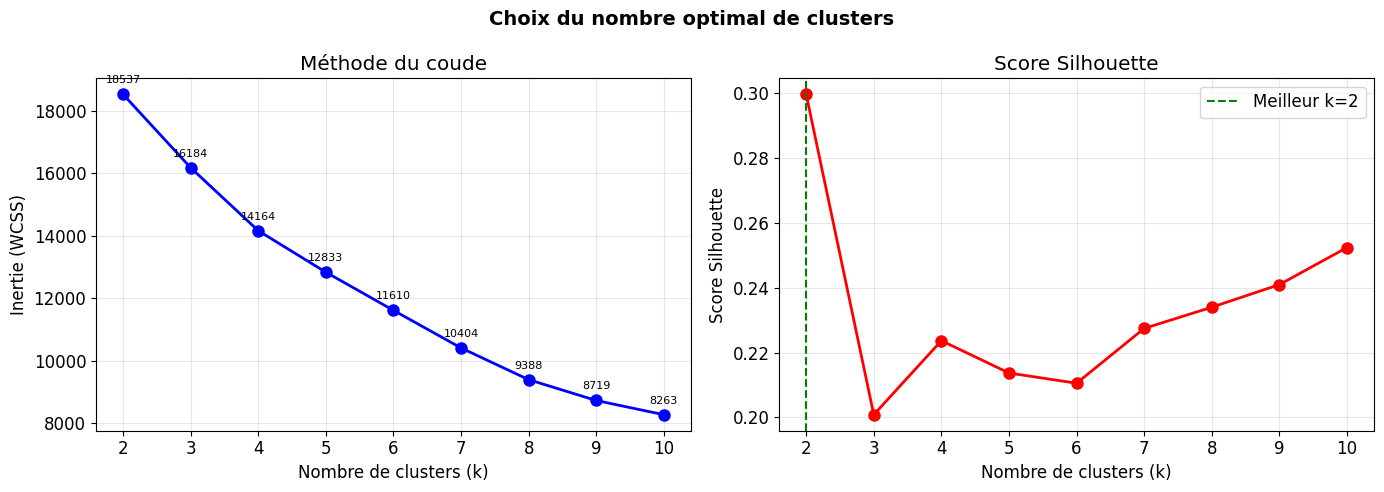


→ Meilleur k selon Silhouette : k=2
→ Pour 3 classes (Bronze/Silver/Gold), nous utiliserons k=3


In [8]:
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=500, random_state=42))
    print(f"k={k} | Inertie={km.inertia_:.0f} | Silhouette={silhouettes[-1]:.4f}")

# Graphique double
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Nombre de clusters (k)')
ax1.set_ylabel('Inertie (WCSS)')
ax1.set_title('Méthode du coude')
ax1.grid(True, alpha=0.3)
for i, (k, v) in enumerate(zip(K_range, inertias)):
    ax1.annotate(f'{v:.0f}', (k, v), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)

ax2.plot(list(K_range), silhouettes, 'ro-', linewidth=2, markersize=8)
ax2.set_xlabel('Nombre de clusters (k)')
ax2.set_ylabel('Score Silhouette')
ax2.set_title('Score Silhouette')
ax2.grid(True, alpha=0.3)

best_k = list(K_range)[np.argmax(silhouettes)]
ax2.axvline(x=best_k, color='green', linestyle='--', label=f'Meilleur k={best_k}')
ax2.legend()

plt.suptitle('Choix du nombre optimal de clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n→ Meilleur k selon Silhouette : k={best_k}")
print(f"→ Pour 3 classes (Bronze/Silver/Gold), nous utiliserons k=3")

## 5. Application de K-Means avec k=3

In [9]:
# Application K-Means avec k=3
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

df_clean = df_clean.copy()
df_clean['cluster'] = cluster_labels

# Calcul du score QoS moyen par cluster (pour mapper sur Bronze/Silver/Gold)
# On calcule un score agrégé simple en re-normalisé les valeurs originales
cluster_means = df_clean.groupby('cluster')[qos_cols].mean()

# Ajustement : pour ResponseTime et Latency, bas = mieux → inverser pour le score
score_matrix = cluster_means.copy()
score_matrix['ResponseTime'] = -score_matrix['ResponseTime']
score_matrix['Latency']      = -score_matrix['Latency']

# Score global = somme normalisée
cluster_scores = score_matrix.mean(axis=1)
rank = cluster_scores.rank(ascending=True).astype(int)  # 1=Bronze, 2=Silver, 3=Gold

label_map_numeric = {cluster: rank[cluster] for cluster in rank.index}
quality_map = {1: 'Bronze', 2: 'Silver', 3: 'Gold'}
cluster_to_label = {c: quality_map[label_map_numeric[c]] for c in label_map_numeric}

print("Mapping clusters → classes qualité :")
for c, lbl in cluster_to_label.items():
    print(f"  Cluster {c}  →  {lbl}  (score moyen = {cluster_scores[c]:.4f})")

print("\nMoyennes QoS par cluster :")
print(cluster_means.round(2))

Mapping clusters → classes qualité :
  Cluster 0  →  Gold  (score moyen = 10.3282)
  Cluster 1  →  Silver  (score moyen = 3.6133)
  Cluster 2  →  Bronze  (score moyen = -30.9529)

Moyennes QoS par cluster :
         ResponseTime  Availability  Throughput  Successability  Reliability  \
cluster                                                                        
0              344.37         88.94       10.96           92.28         73.8   
1              350.40         88.77        7.83           91.94         60.8   
2              534.72         50.15        5.03           50.68         69.1   

         Compliance  BestPractices  Latency  Documentation  
cluster                                                     
0             90.16          83.61    32.69          30.25  
1             88.83          69.35    53.85          29.25  
2             83.09          78.94   117.63          36.79  


## 6. Génération du nouveau dataset avec la colonne `class`

In [10]:
# Ajout de la colonne 'class'
df_clean['class'] = df_clean['cluster'].map(cluster_to_label)

# Dataset final : garder les 9 QoS + ServiceName + WSDLAddress + class
df_final = df_clean[qos_cols + ['ServiceName', 'WSDLAddress', 'class']].reset_index(drop=True)

print("=== Distribution des classes ===")
vc = df_final['class'].value_counts()
print(vc)
print(f"\nTotal services : {len(df_final)}")

print("\n=== Aperçu du nouveau dataset ===")
df_final.head(10)

=== Distribution des classes ===
class
Gold      1413
Silver     593
Bronze     501
Name: count, dtype: int64

Total services : 2507

=== Aperçu du nouveau dataset ===


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation,ServiceName,WSDLAddress,class
0,302.75,89,7.1,90,73,78,80,187.75,32,MAPPMatching,http://xml.assessment.com/service/MAPPMatching...,Gold
1,482.00,85,16.0,95,73,100,84,1.00,2,Compound2,http://www.mssoapinterop.org/asmx/WSDL/compoun...,Gold
2,3321.40,89,1.4,96,73,78,80,2.60,96,USDAData,http://www.strikeiron.com/webservices/usdadata...,Gold
3,126.17,98,12.0,100,67,78,82,22.77,89,GBNIRHolidayDates,http://www.holidaywebservice.com/Holidays/GBNI...,Gold
4,107.00,87,1.9,95,73,89,62,58.33,93,CasUsers,http://galex.stsci.edu/casjobs/CasUsers.asmx?WSDL,Silver
5,107.57,80,1.7,81,67,78,82,18.21,61,interop2,http://websrv.cs.fsu.edu/~engelen/interop2_2.wsdl,Gold
6,255.00,98,1.3,99,67,100,82,40.80,4,ehmmpfamService,http://www.ebi.ac.uk/soaplab/emboss4/services/...,Gold
7,136.71,76,2.8,76,60,89,69,11.57,8,WSDBFetchServerLegacyService,http://www.embl-ebi.ac.uk/Tools/webservices/ws...,Silver
8,102.62,91,15.3,97,67,78,82,0.93,91,DOTSPackageTracking,http://trial.serviceobjects.com/pt/PackTrack.a...,Gold
9,93.37,96,13.5,99,67,89,58,41.66,93,CommandService,http://www.leadtools.net/Services/CommandServi...,Silver


## 7. Visualisation des clusters

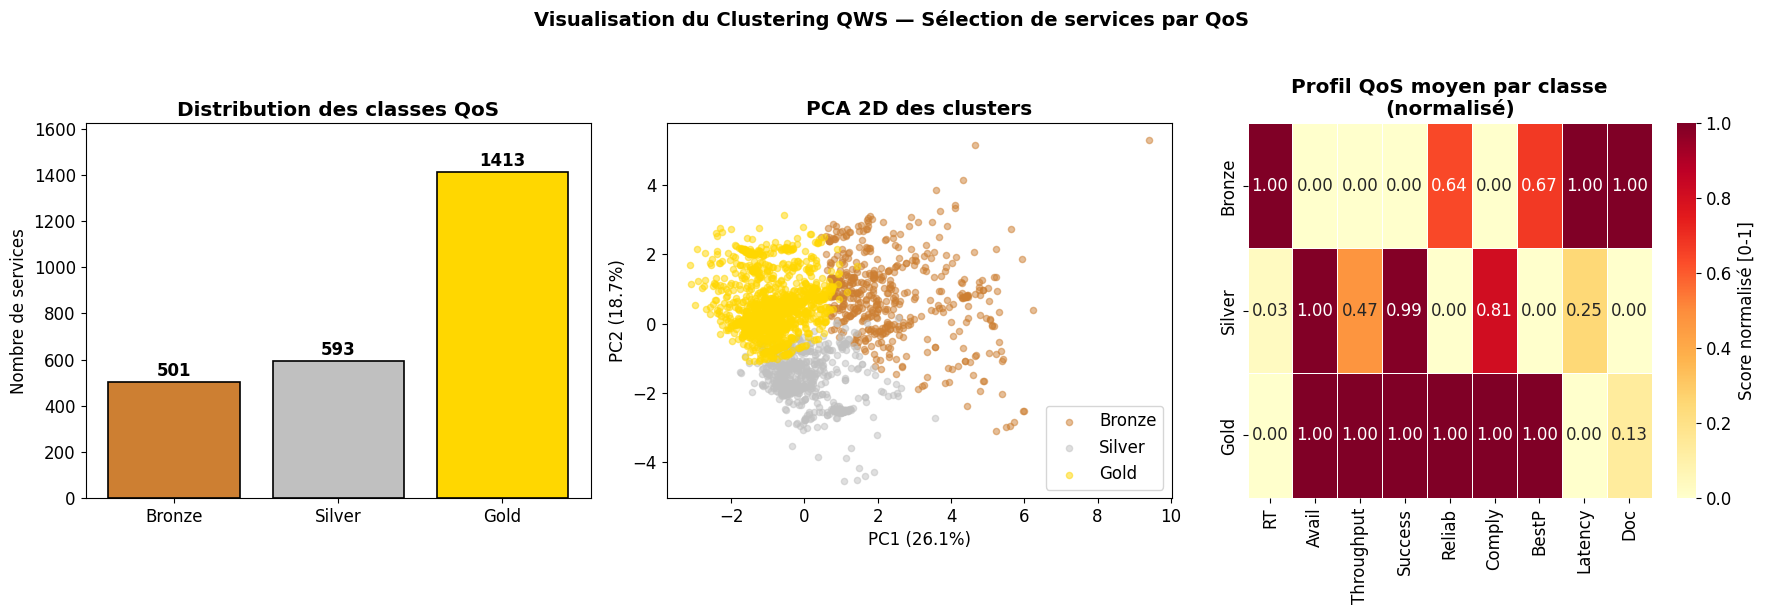


Variance expliquée PCA : PC1=26.1%  PC2=18.7%


In [11]:
color_map = {'Bronze': '#CD7F32', 'Silver': '#C0C0C0', 'Gold': '#FFD700'}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Plot 1 : Distribution des classes (bar chart) ---
ax1 = axes[0]
classes = ['Bronze', 'Silver', 'Gold']
counts  = [df_final[df_final['class'] == c].shape[0] for c in classes]
bars = ax1.bar(classes, counts, color=[color_map[c] for c in classes], edgecolor='black', linewidth=1.2)
ax1.set_title('Distribution des classes QoS', fontweight='bold')
ax1.set_ylabel('Nombre de services')
for bar, cnt in zip(bars, counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             str(cnt), ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, max(counts) * 1.15)

# --- Plot 2 : PCA 2D des clusters ---
ax2 = axes[1]
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
for cls in classes:
    mask = df_final['class'] == cls
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=color_map[cls], label=cls, alpha=0.5, s=20)
ax2.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax2.set_title('PCA 2D des clusters', fontweight='bold')
ax2.legend()

# --- Plot 3 : Heatmap des moyennes QoS par classe ---
ax3 = axes[2]
means_by_class = df_final.groupby('class')[qos_cols].mean().loc[classes]
short_cols = ['RT', 'Avail', 'Throughput', 'Success', 'Reliab', 'Comply', 'BestP', 'Latency', 'Doc']
means_norm = (means_by_class - means_by_class.min()) / (means_by_class.max() - means_by_class.min())
means_norm.columns = short_cols
sns.heatmap(means_norm, ax=ax3, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Score normalisé [0-1]'})
ax3.set_title('Profil QoS moyen par classe\n(normalisé)', fontweight='bold')
ax3.set_ylabel('')

plt.suptitle('Visualisation du Clustering QWS — Sélection de services par QoS',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('qws_clusters_visualisation.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nVariance expliquée PCA : PC1={pca.explained_variance_ratio_[0]*100:.1f}%  PC2={pca.explained_variance_ratio_[1]*100:.1f}%")

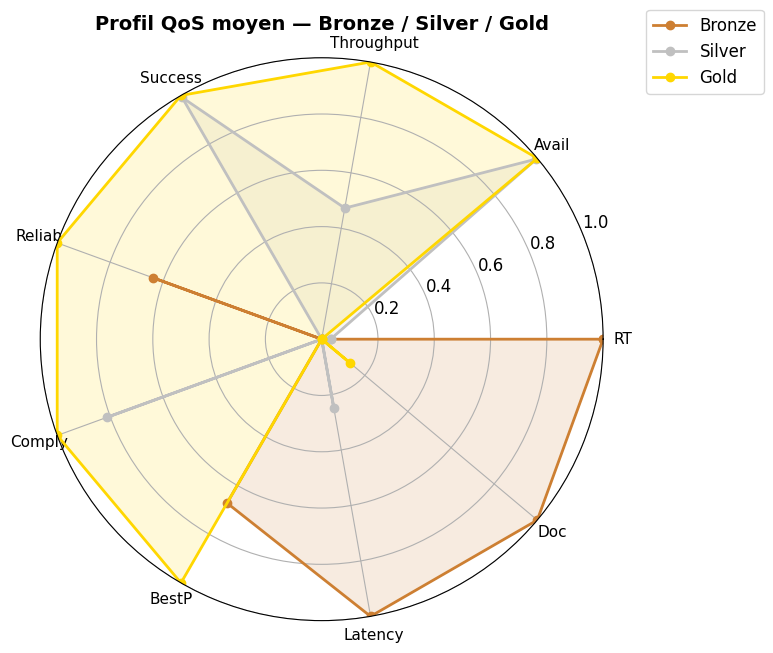

In [12]:
# Radar chart (graphique en araignée) pour comparer les profils QoS des 3 classes
short_cols = ['RT', 'Avail', 'Throughput', 'Success', 'Reliab', 'Comply', 'BestP', 'Latency', 'Doc']
N = len(short_cols)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # fermer le polygone

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for cls in ['Bronze', 'Silver', 'Gold']:
    values = means_norm.loc[cls].values.tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=cls, color=color_map[cls])
    ax.fill(angles, values, alpha=0.15, color=color_map[cls])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(short_cols, size=11)
ax.set_ylim(0, 1)
ax.set_title('Profil QoS moyen — Bronze / Silver / Gold', size=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig('qws_radar_chart.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Export du nouveau dataset avec la colonne `class`

In [13]:
# Sauvegarde du dataset complet (QoS + ServiceName + WSDLAddress + class)
output_path = 'qws2_avec_class.csv'
df_final.to_csv(output_path, index=False)
print(f"Dataset sauvegardé : {output_path}")
print(f"Shape : {df_final.shape}   ({df_final.shape[0]} services, {df_final.shape[1]} colonnes)")

# Sauvegarde uniquement des services Gold (les meilleurs — pour la composition)
df_gold = df_final[df_final['class'] == 'Gold'].reset_index(drop=True)
df_gold.to_csv('qws2_gold_services.csv', index=False)
print(f"\nServices Gold sauvegardés : qws2_gold_services.csv  ({len(df_gold)} services)")

# Résumé final
print("\n=== RÉSUMÉ FINAL ===")
print(df_final['class'].value_counts().to_string())
print(f"\nColonnes du nouveau dataset :")
print(list(df_final.columns))
print("\n=== Aperçu final ===")
df_final.sample(10, random_state=42)

Dataset sauvegardé : qws2_avec_class.csv
Shape : (2507, 12)   (2507 services, 12 colonnes)

Services Gold sauvegardés : qws2_gold_services.csv  (1413 services)

=== RÉSUMÉ FINAL ===
class
Gold      1413
Silver     593
Bronze     501

Colonnes du nouveau dataset :
['ResponseTime', 'Availability', 'Throughput', 'Successability', 'Reliability', 'Compliance', 'BestPractices', 'Latency', 'Documentation', 'ServiceName', 'WSDLAddress', 'class']

=== Aperçu final ===


,ResponseTime,Availability,Throughput,Successability,Reliability,Compliance,BestPractices,Latency,Documentation,ServiceName,WSDLAddress,class
2121,176.25,89,7.1,90,80,89,83,39.50,10,WSDLInteropTestDocLitService,http://www.whitemesa.com/r3/InteropTestDocLit....,Gold
56,1035.00,71,8.4,72,73,78,88,6.00,11,PathFinderService,http://www.sephiroth.it/webservices/pathfinder...,Gold
2479,113.50,96,1.3,99,60,100,79,24.00,10,ZacksSummary,http://ws.strikeiron.com/ZacksSummary?WSDL,Silver
1292,46.05,89,20.7,96,67,100,77,4.48,8,AWSMechanicalTurkRequester,http://mechanicalturk.amazonaws.com/AWSMechani...,Gold
1599,226.60,95,15.5,98,73,100,84,6.60,42,diffseqService,http://genome.dkfz-heidelberg.de/menu/hobit/em...,Gold
801,843.50,97,5.7,99,58,89,69,98.50,9,NavneNumreBasis,http://tunnel.nno.dk/NNService/1.0/NNService.wsdl,Silver
170,180.00,83,13.5,84,73,78,84,7.00,9,eFetchService,http://www.ncbi.nlm.nih.gov/entrez/eutils/soap...,Gold
940,310.74,86,3.6,86,53,89,66,93.78,2,AnalysisWSAppLabImplService,http://www.ebi.ac.uk/soaplab/emboss4/services/...,Silver
988,452.75,88,4.5,96,67,100,72,142.25,88,LORAX,http://lex.thelearningfederation.edu.au/WebSer...,Silver
819,144.75,56,10.7,56,73,89,75,4.50,1,CReasonerService,http://ws.comtec.e-technik.uni-kassel.de/axis/...,Bronze
